In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F 
import torch.optim as optim

import torchvision 
import torchvision.transforms as transforms


import matplotlib.pyplot as plt 
import numpy as np 

from torch.utils.tensorboard import SummaryWriter

In [15]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,))
])

In [16]:
training_set= torchvision.datasets.FashionMNIST(
    root="./",
    download=True,
    train=True,
    transform=transform
)
validation_set= torchvision.datasets.FashionMNIST(
    root="./",
    download=True,
    train=False,
    transform=transform
)

In [17]:
training_loader= torch.utils.data.DataLoader(training_set, batch_size=4,
shuffle=True, num_workers=2)
validation_loader= torch.utils.data.DataLoader(validation_set, batch_size=4, shuffle=False, num_workers=2)

In [18]:
classes= ("T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle Boot")

In [19]:
def matplot_imshow(img, one_channel=False):
    if one_channel:
        img= img.mean(dim=0)
    img= img/2+0.5
    npimg=img.numpy()

    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1,2,0)))


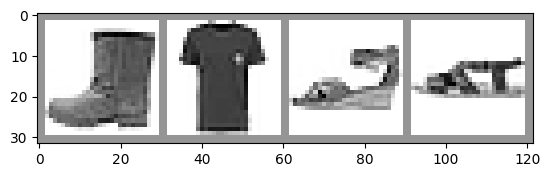

In [20]:

dataiter = iter(training_loader)
images, labels = next(dataiter)

img_grid=torchvision.utils.make_grid(images)
matplot_imshow(img_grid, True)

In [21]:
writer=SummaryWriter("runs/fashion_mnist_experiment_1")
writer.add_image("Four Fashion Mnist Image", img_grid)
writer.flush()

In [ ]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()

        self.conv1= nn.Conv2d(1,6,5)
        self.pool= nn.MaxPool2d(2,2)
        self.conv2= nn.Conv2d(6,16,5)
        self.fc1= nn.Linear(16*4*4, 120)
        self.fc2= nn.Linear(120, 84)
        self.fc3= nn.Linear(84, 10)


    def forward(self, x):
        x= self.pool(F.relu(self.conv1(x)))
        x= self.pool(F.relu(self.conv2(x)))
        x= x.view(-1, 16 *4*4)
        x= F.relu(self.fc1(x))
        x= F.relu(self.fc2(x))
        x= self.fc3(x)
        return x